In [1]:
# ============================================================
# APEXPLANET DATA ANALYTICS INTERNSHIP
# TASK 4: ADVANCED ANALYTICS
# ============================================================

# 1. Import libraries

import os
import warnings
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# 2. Visualization settings

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120

# 3. Load cleaned dataset

df = pd.read_csv(
    "data/superstore_clean.csv",
    encoding="utf-8-sig"
)

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# 4. Create output directories

os.makedirs("reports", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

# 5. Dataset validation

print("=" * 60)
print("ADVANCED ANALYTICS - DATASET VALIDATION")
print("=" * 60)

print("Dataset Shape:", df.shape)
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nDataset loaded successfully!")

display(df.head())

ADVANCED ANALYTICS - DATASET VALIDATION
Dataset Shape: (10194, 21)
Total Records: 10194
Total Columns: 21
Missing Values: 0
Duplicate Records: 0

Dataset loaded successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [2]:
# ============================================================
# 4.1 DESCRIPTIVE STATISTICS
# ============================================================

numerical_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

descriptive_stats = df[numerical_columns].describe().T

descriptive_stats["median"] = df[numerical_columns].median()
descriptive_stats["mode"] = df[numerical_columns].mode().iloc[0]
descriptive_stats["variance"] = df[numerical_columns].var()
descriptive_stats["skewness"] = df[numerical_columns].skew()
descriptive_stats["kurtosis"] = df[numerical_columns].kurtosis()

print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)

display(descriptive_stats.round(4))

descriptive_stats.to_csv(
    "reports/descriptive_statistics.csv"
)

print("Descriptive statistics saved successfully!")

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,median,mode,variance,skewness,kurtosis
Sales,10194.0,228.2259,619.9068,0.444,17.2200,53.91,209.5000,22638.480,53.91,12.96,384284.4888,12.9839,306.3663
Quantity,10194.0,3.7918,2.2283,1.000,2.0000,3.00,5.0000,14.000,3.00,2.00,4.9654,1.2686,1.9615
Discount,10194.0,0.1554,0.2062,0.000,0.0000,0.20,0.2000,0.800,0.20,0.00,0.0425,1.6875,2.4163
Profit,10194.0,28.6734,232.4651,-6599.978,1.7608,8.69,29.2979,8399.976,8.69,0.00,54040.0297,7.6049,401.6929


Descriptive statistics saved successfully!


CORRELATION MATRIX


,Sales,Quantity,Discount,Profit
Sales,1.0000,0.1985,-0.0278,0.4815
Quantity,0.1985,1.0000,0.0075,0.0661
Discount,-0.0278,0.0075,1.0000,-0.2189
Profit,0.4815,0.0661,-0.2189,1.0000


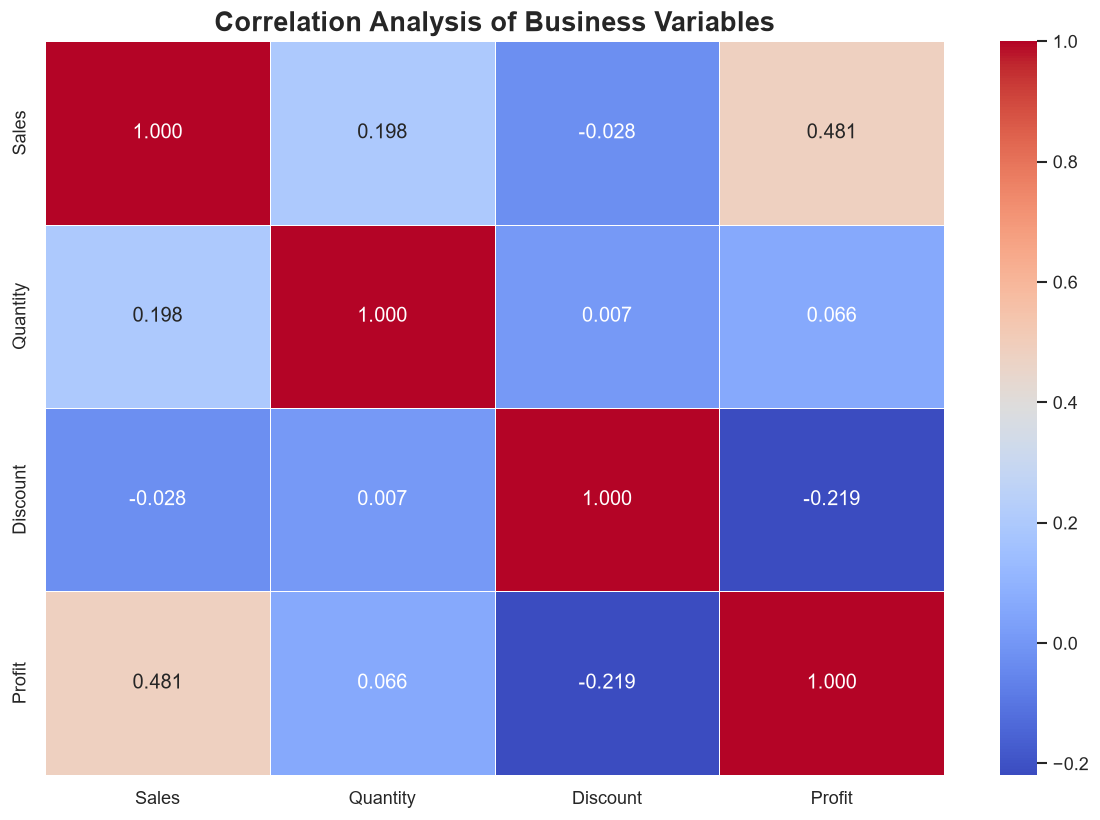

Correlation analysis completed!


In [3]:
# ============================================================
# 4.2 CORRELATION ANALYSIS
# ============================================================

correlation_matrix = df[
    ["Sales", "Quantity", "Discount", "Profit"]
].corr()

print("CORRELATION MATRIX")

display(correlation_matrix.round(4))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5
)

plt.title(
    "Correlation Analysis of Business Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "visualizations/11_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

correlation_matrix.to_csv(
    "reports/correlation_analysis.csv"
)

print("Correlation analysis completed!")

In [4]:
# ============================================================
# 4.3 CUSTOMER SEGMENTATION
# ============================================================

customer_data = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean"),
    Total_Profit=("Profit", "sum")
).reset_index()

print("CUSTOMER DATASET CREATED")

print("Total Customers:", len(customer_data))
print("Dataset Shape:", customer_data.shape)

display(customer_data.head())

CUSTOMER DATASET CREATED
Total Customers: 804
Dataset Shape: (804, 7)


,Customer ID,Customer Name,Total_Sales,Total_Orders,Total_Quantity,Average_Discount,Total_Profit
0,AA-10315,Alex Avila,5563.560,5,30,0.090909,-362.8825
1,AA-10375,Allen Armold,1056.390,9,41,0.080000,277.3824
2,AA-10480,Andrew Allen,1790.512,4,36,0.016667,435.8274
3,AA-10645,Anna Andreadi,5086.935,6,64,0.063889,857.8033
4,AB-10015,Aaron Bergman,886.156,3,13,0.066667,129.3465


In [5]:
# ============================================================
# CUSTOMER SEGMENTATION - FEATURE SCALING
# ============================================================

segmentation_features = [
    "Total_Sales",
    "Total_Orders",
    "Total_Quantity",
    "Average_Discount",
    "Total_Profit"
]

X = customer_data[segmentation_features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=segmentation_features
)

print("FEATURE SCALING COMPLETED")

display(scaled_df.head())

print("\nScaled Feature Means:")
print(scaled_df.mean().round(4))

print("\nScaled Feature Standard Deviations:")
print(scaled_df.std(ddof=0).round(4))

FEATURE SCALING COMPLETED


,Total_Sales,Total_Orders,Total_Quantity,Average_Discount,Total_Profit
0,1.006686,-0.513239,-0.692876,-0.723258,-0.813953
1,-0.692768,0.991388,-0.271258,-0.841380,-0.096552
2,-0.415963,-0.889396,-0.462903,-1.527146,0.080981
3,0.826972,-0.137082,0.610307,-1.015830,0.553795
4,-0.756956,-1.265552,-1.344468,-0.985752,-0.262423



Scaled Feature Means:
Total_Sales         0.0
Total_Orders       -0.0
Total_Quantity     -0.0
Average_Discount   -0.0
Total_Profit        0.0
dtype: float64

Scaled Feature Standard Deviations:
Total_Sales         1.0
Total_Orders        1.0
Total_Quantity      1.0
Average_Discount    1.0
Total_Profit        1.0
dtype: float64


,Number of Clusters,Inertia
0,1,4020.00
1,2,2781.53
2,3,2323.76
3,4,1929.27
4,5,1741.73
5,6,1554.30
6,7,1400.59
7,8,1277.49
8,9,1175.52
9,10,1096.70


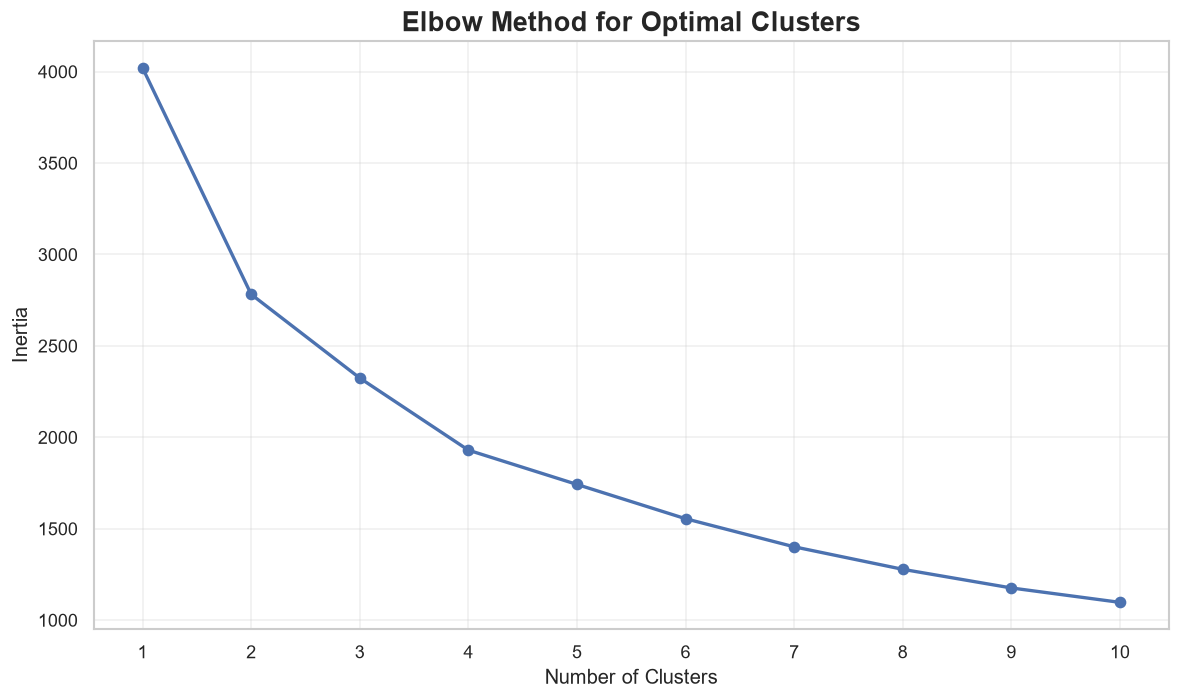

Elbow method completed!


In [6]:
# ============================================================
# 4.4 ELBOW METHOD
# ============================================================

inertia_values = []

K = range(1, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

elbow_results = pd.DataFrame({
    "Number of Clusters": list(K),
    "Inertia": inertia_values
})

display(elbow_results.round(2))

plt.figure(figsize=(10, 6))

plt.plot(
    K,
    inertia_values,
    marker="o",
    linewidth=2
)

plt.title(
    "Elbow Method for Optimal Clusters",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(K))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "visualizations/12_elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Elbow method completed!")

,Number of Clusters,Silhouette Score
0,2,0.3139
1,3,0.2810
2,4,0.2568
3,5,0.2565
4,6,0.2614
5,7,0.2597
6,8,0.2339
7,9,0.2353
8,10,0.2269


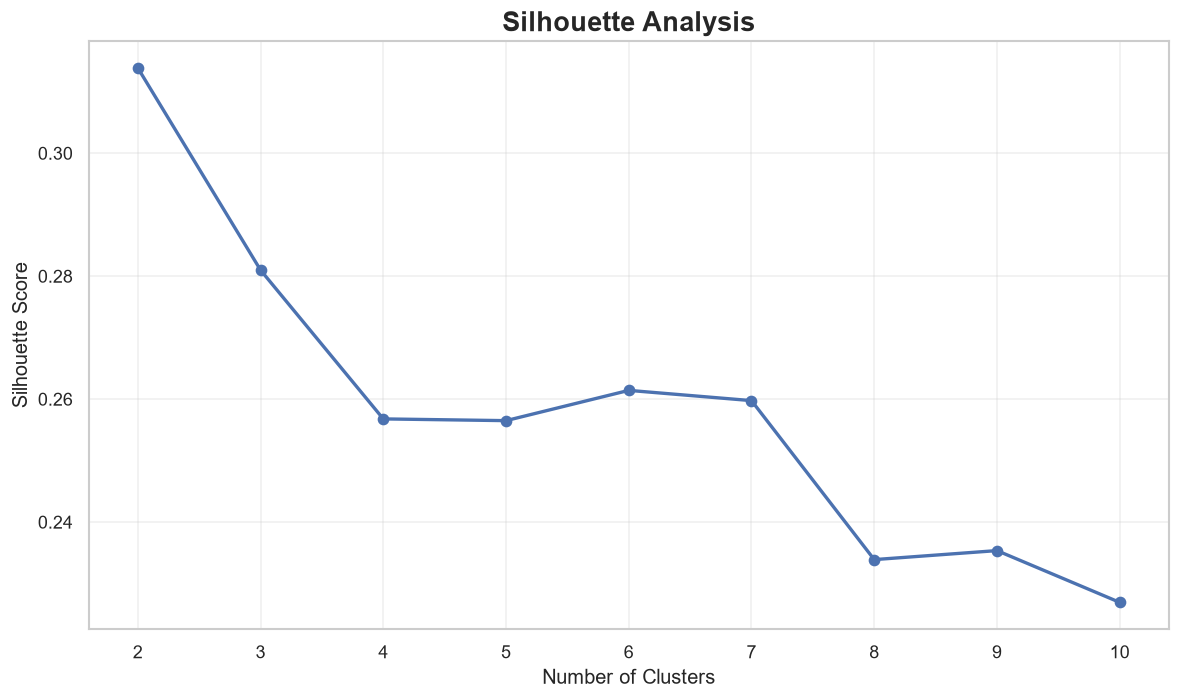

Best Silhouette Cluster Count: 2


In [7]:
# ============================================================
# 4.5 SILHOUETTE ANALYSIS
# ============================================================

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

silhouette_results = pd.DataFrame({
    "Number of Clusters": list(range(2, 11)),
    "Silhouette Score": silhouette_scores
})

display(silhouette_results.round(4))

plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o",
    linewidth=2
)

plt.title(
    "Silhouette Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "visualizations/13_silhouette_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best Silhouette Cluster Count:", best_k)

In [8]:
# ============================================================
# FINAL CUSTOMER SEGMENTATION
# ============================================================

final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_data["Customer_Segment"] = (
    final_kmeans.fit_predict(X_scaled)
)

segment_distribution = (
    customer_data["Customer_Segment"]
    .value_counts()
    .sort_index()
)

print("CUSTOMER SEGMENT DISTRIBUTION")

display(
    segment_distribution.to_frame("Customer Count")
)

segment_profile = customer_data.groupby(
    "Customer_Segment"
)[segmentation_features].mean()

segment_profile["Customer_Count"] = (
    customer_data.groupby("Customer_Segment").size()
)

display(segment_profile.round(2))

# Assign descriptive labels based on segment averages

higher_value_segment = segment_profile[
    "Total_Sales"
].idxmax()

customer_data["Segment_Name"] = customer_data[
    "Customer_Segment"
].map({
    higher_value_segment: "Higher-Value Customers",
    1 - higher_value_segment: "Lower-Value Customers"
})

# Save reports

customer_data.to_csv(
    "reports/customer_segmentation.csv",
    index=False
)

segment_profile.to_csv(
    "reports/customer_segment_profile.csv"
)

print("Customer segmentation saved successfully!")

CUSTOMER SEGMENT DISTRIBUTION


,Customer Count
Customer_Segment,
0,486
1,318


,Total_Sales,Total_Orders,Total_Quantity,Average_Discount,Total_Profit,Customer_Count
Customer_Segment,,,,,,
0,1602.76,4.83,32.65,0.16,104.70,486
1,4866.65,8.71,71.65,0.15,759.15,318


Customer segmentation saved successfully!


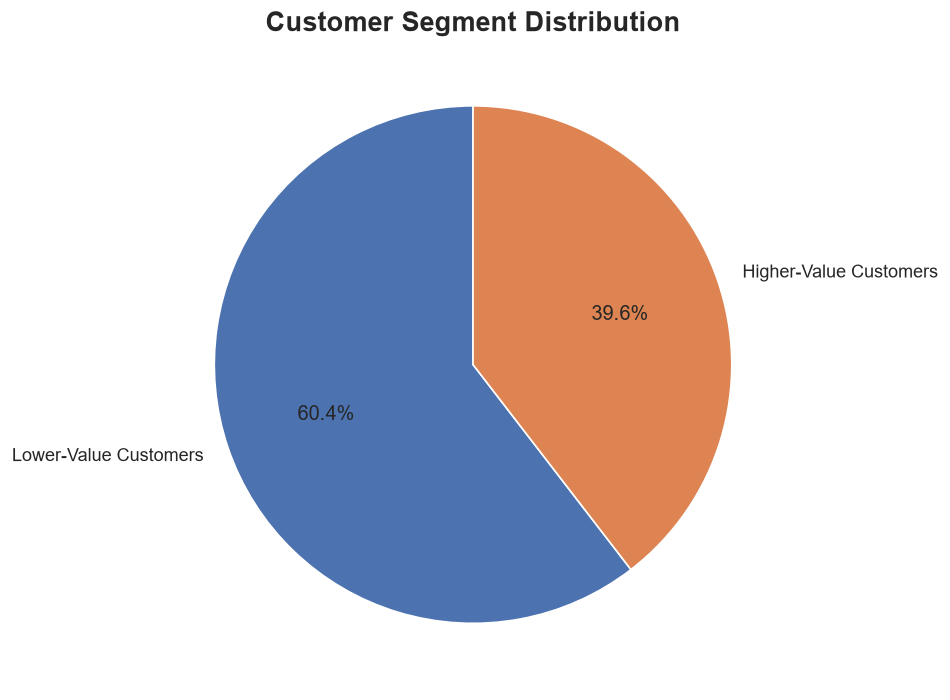

Visualization 14 saved successfully!


In [9]:
# ============================================================
# VISUALIZATION 14: CUSTOMER SEGMENT DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 6))

segment_counts = customer_data["Segment_Name"].value_counts()

plt.pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Customer Segment Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "visualizations/14_customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualization 14 saved successfully!")

AVERAGE SALES AND PROFIT BY CUSTOMER SEGMENT


,Total_Sales,Total_Profit
Segment_Name,,
Higher-Value Customers,4866.65,759.15
Lower-Value Customers,1602.76,104.70


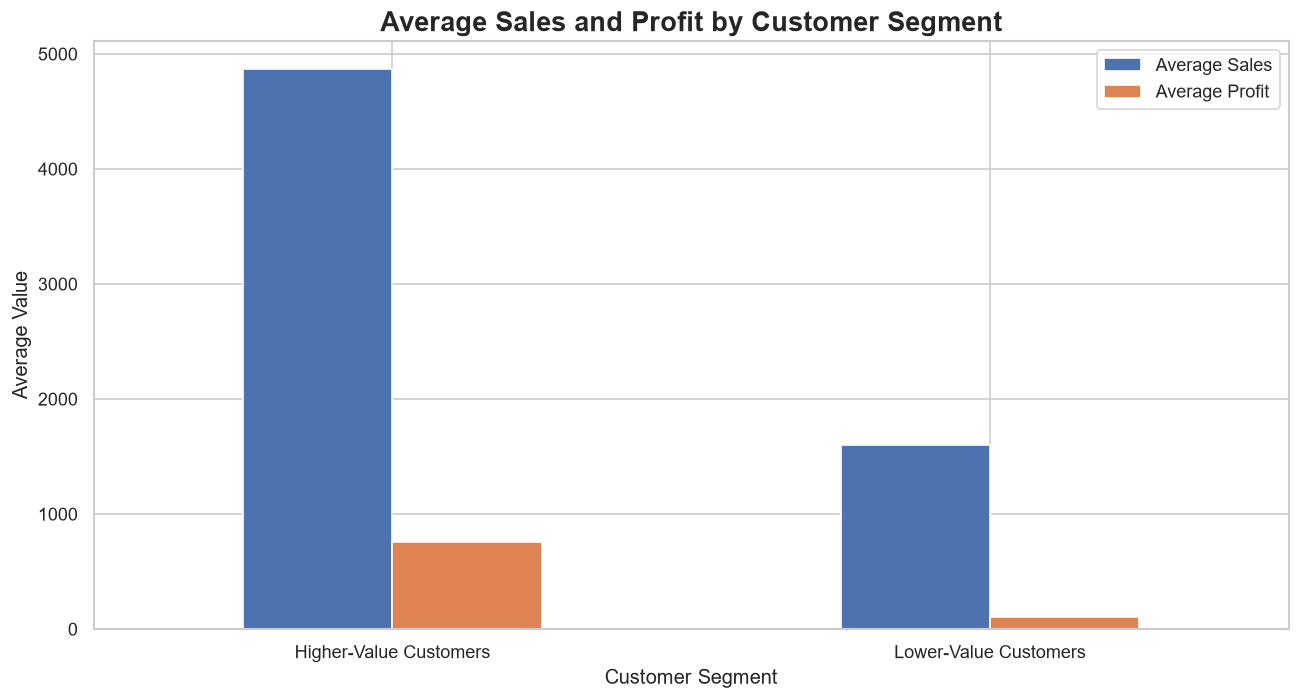

Visualization 15 saved successfully!


In [10]:
# ============================================================
# VISUALIZATION 15: SEGMENT SALES AND PROFIT COMPARISON
# ============================================================

segment_comparison = customer_data.groupby(
    "Segment_Name"
)[["Total_Sales", "Total_Profit"]].mean()

print("AVERAGE SALES AND PROFIT BY CUSTOMER SEGMENT")

display(segment_comparison.round(2))

segment_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Average Sales and Profit by Customer Segment",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segment")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(["Average Sales", "Average Profit"])

plt.tight_layout()

plt.savefig(
    "visualizations/15_segment_sales_profit_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualization 15 saved successfully!")

In [11]:
# ============================================================
# 4.6 PROFIT PREDICTION - DATA PREPARATION
# ============================================================

model_df = df[
    [
        "Sales",
        "Quantity",
        "Discount",
        "Category",
        "Sub-Category",
        "Region",
        "Segment",
        "Ship Mode",
        "Profit"
    ]
].copy()

print("=" * 60)
print("PREDICTIVE MODELING DATASET")
print("=" * 60)

print("Dataset Shape:", model_df.shape)
print("Missing Values:", model_df.isnull().sum().sum())

print("\nTarget Variable Summary:")

display(model_df["Profit"].describe().to_frame())

display(model_df.head())

print("Modeling dataset prepared successfully!")

PREDICTIVE MODELING DATASET
Dataset Shape: (10194, 9)
Missing Values: 0

Target Variable Summary:


,Profit
count,10194.000000
mean,28.673417
std,232.465115
min,-6599.978000
25%,1.760800
50%,8.690000
75%,29.297925
max,8399.976000


,Sales,Quantity,Discount,Category,Sub-Category,Region,Segment,Ship Mode,Profit
0,16.448,2,0.2,Office Supplies,Paper,Central,Consumer,Standard Class,5.5512
1,3.540,2,0.8,Office Supplies,Binders,Central,Home Office,Standard Class,-5.4870
2,11.784,3,0.2,Office Supplies,Labels,Central,Home Office,Standard Class,4.2717
3,272.736,3,0.2,Office Supplies,Storage,Central,Home Office,Standard Class,-64.7748
4,19.536,3,0.2,Office Supplies,Art,East,Consumer,Standard Class,4.8840


Modeling dataset prepared successfully!


In [12]:
# ============================================================
# FEATURE AND TARGET SEPARATION
# ============================================================

X = model_df.drop(columns=["Profit"])

y = model_df["Profit"]

categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

numerical_features = [
    "Sales",
    "Quantity",
    "Discount"
]

print("FEATURES:", list(X.columns))

print("\nTARGET:", "Profit")

print("\nNumerical Features:", numerical_features)

print("\nCategorical Features:", categorical_features)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

FEATURES: ['Sales', 'Quantity', 'Discount', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

TARGET: Profit

Numerical Features: ['Sales', 'Quantity', 'Discount']

Categorical Features: ['Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']

X Shape: (10194, 8)
y Shape: (10194,)


In [13]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("TRAINING AND TESTING DATA")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

TRAINING AND TESTING DATA
Training Features: (8155, 8)
Testing Features: (2039, 8)
Training Target: (8155,)
Testing Target: (2039,)

Training Records: 8155
Testing Records: 2039


In [14]:
# ============================================================
# FEATURE PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING COMPLETED")

print("Processed Training Shape:", X_train_processed.shape)

print("Processed Testing Shape:", X_test_processed.shape)

print(
    "Total Processed Features:",
    X_train_processed.shape[1]
)

PREPROCESSING COMPLETED
Processed Training Shape: (8155, 34)
Processed Testing Shape: (2039, 34)
Total Processed Features: 34


In [15]:
# ============================================================
# TRAIN REGRESSION MODELS
# ============================================================

models = {
    "Dummy Regressor": DummyRegressor(
        strategy="mean"
    ),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(
        X_train_processed,
        y_train
    )

    trained_models[name] = model

    print(name, "training completed!")

print("\nALL MODELS TRAINED SUCCESSFULLY!")


Training: Dummy Regressor
Dummy Regressor training completed!

Training: Linear Regression
Linear Regression training completed!

Training: Random Forest
Random Forest training completed!

ALL MODELS TRAINED SUCCESSFULLY!


In [16]:
# ============================================================
# MODEL EVALUATION
# ============================================================

results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test_processed)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("=" * 70)
print("REGRESSION MODEL EVALUATION")
print("=" * 70)

display(results_df.round(4))

results_df.to_csv(
    "reports/model_evaluation_results.csv",
    index=False
)

print("Model evaluation report saved successfully!")

REGRESSION MODEL EVALUATION


,Model,MAE,RMSE,R2 Score
0,Random Forest,20.4557,137.9378,0.7879
1,Linear Regression,61.7601,214.0025,0.4896
2,Dummy Regressor,66.7701,299.7909,-0.0017


Model evaluation report saved successfully!


In [17]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("BEST MODEL:", best_model_name)

display(
    results_df[
        results_df["Model"] == best_model_name
    ].round(4)
)

y_pred = best_model.predict(X_test_processed)

print("Best model selected successfully!")

BEST MODEL: Random Forest


,Model,MAE,RMSE,R2 Score
0,Random Forest,20.4557,137.9378,0.7879


Best model selected successfully!


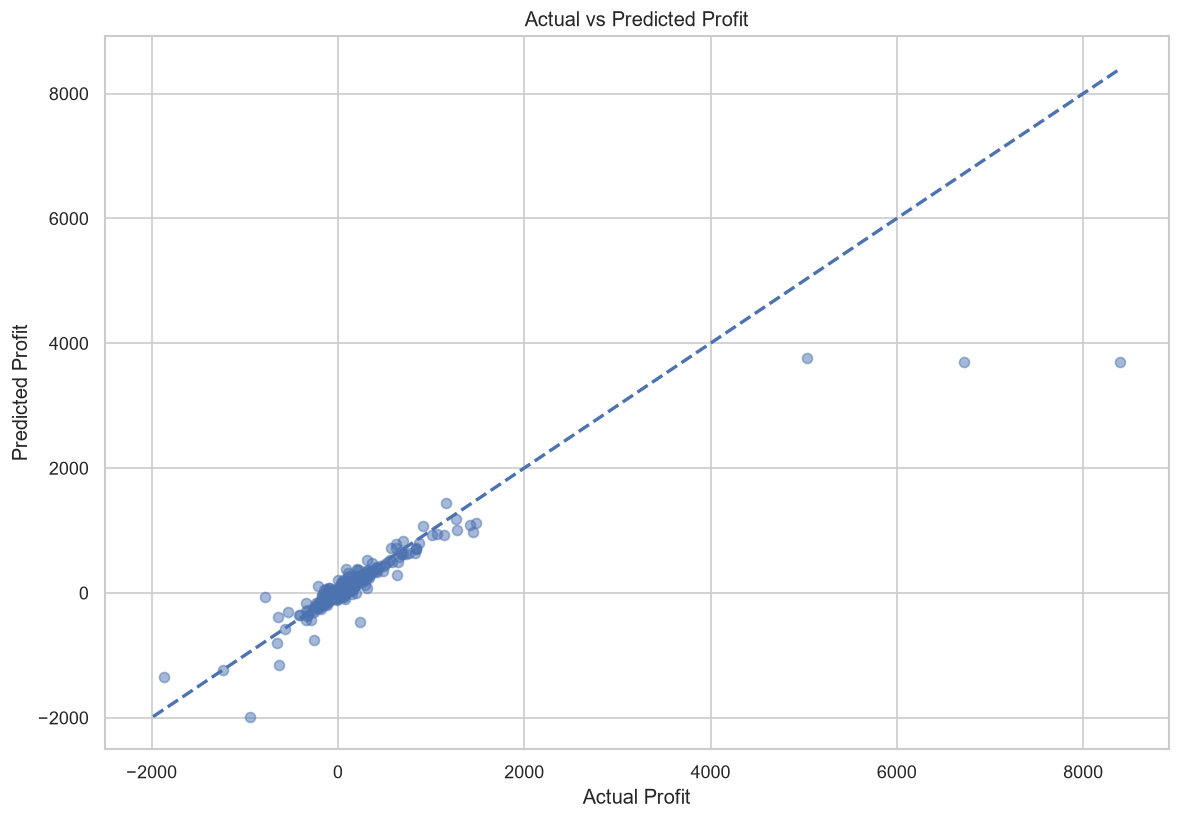

Visualization 16 saved successfully!


In [18]:
plt.figure(figsize=(10, 7))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.tight_layout()

plt.savefig(
    "visualizations/16_actual_vs_predicted_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualization 16 saved successfully!")

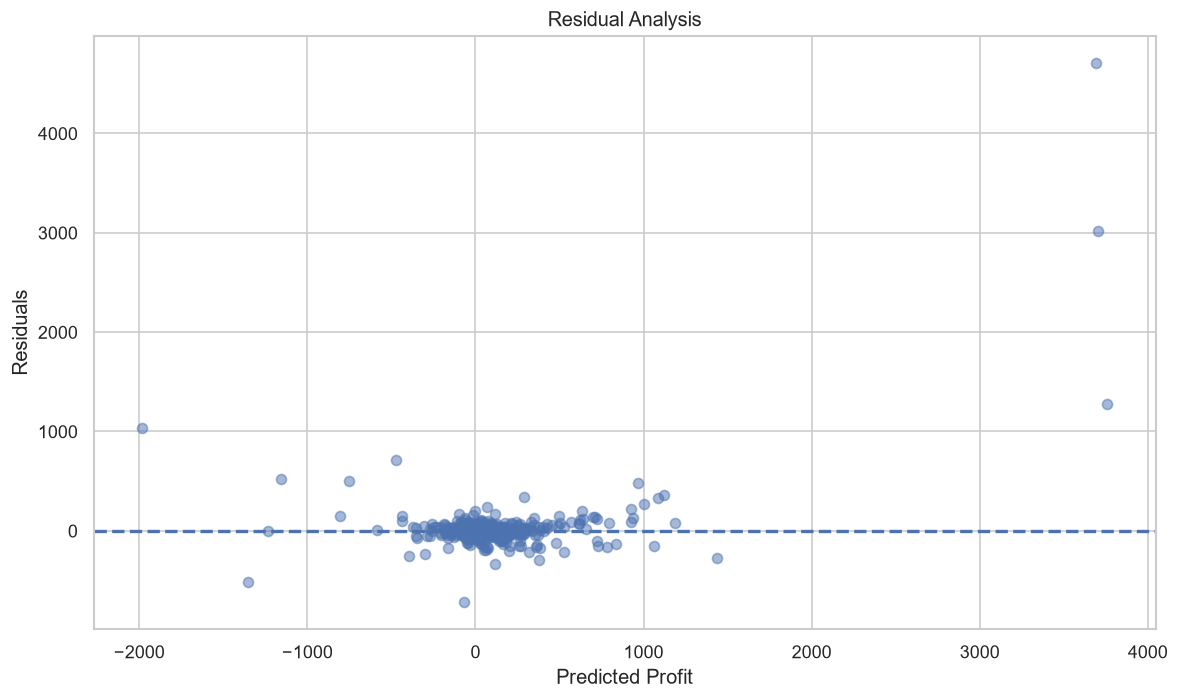

,Metric,Value
0,Mean Residual,6.0601
1,Residual Standard Deviation,137.8384
2,Maximum Residual,4707.3366
3,Minimum Residual,-717.4839


Residual analysis saved successfully!


In [19]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, linestyle="--", linewidth=2)

plt.title("Residual Analysis")
plt.xlabel("Predicted Profit")
plt.ylabel("Residuals")

plt.tight_layout()

plt.savefig(
    "visualizations/17_residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

residual_report = pd.DataFrame({
    "Metric": [
        "Mean Residual",
        "Residual Standard Deviation",
        "Maximum Residual",
        "Minimum Residual"
    ],
    "Value": [
        residuals.mean(),
        residuals.std(),
        residuals.max(),
        residuals.min()
    ]
})

display(residual_report.round(4))

residual_report.to_csv(
    "reports/residual_analysis.csv",
    index=False
)

print("Residual analysis saved successfully!")

TOP 15 IMPORTANT FEATURES


,Feature,Importance
0,numerical__Sales,0.5634
1,numerical__Discount,0.2931
2,numerical__Quantity,0.0218
3,categorical__Sub-Category_Binders,0.0162
4,categorical__Sub-Category_Supplies,0.0154
5,categorical__Region_South,0.0129
6,categorical__Sub-Category_Copiers,0.0090
7,categorical__Sub-Category_Machines,0.0080
8,categorical__Category_Furniture,0.0061
9,categorical__Region_East,0.0053


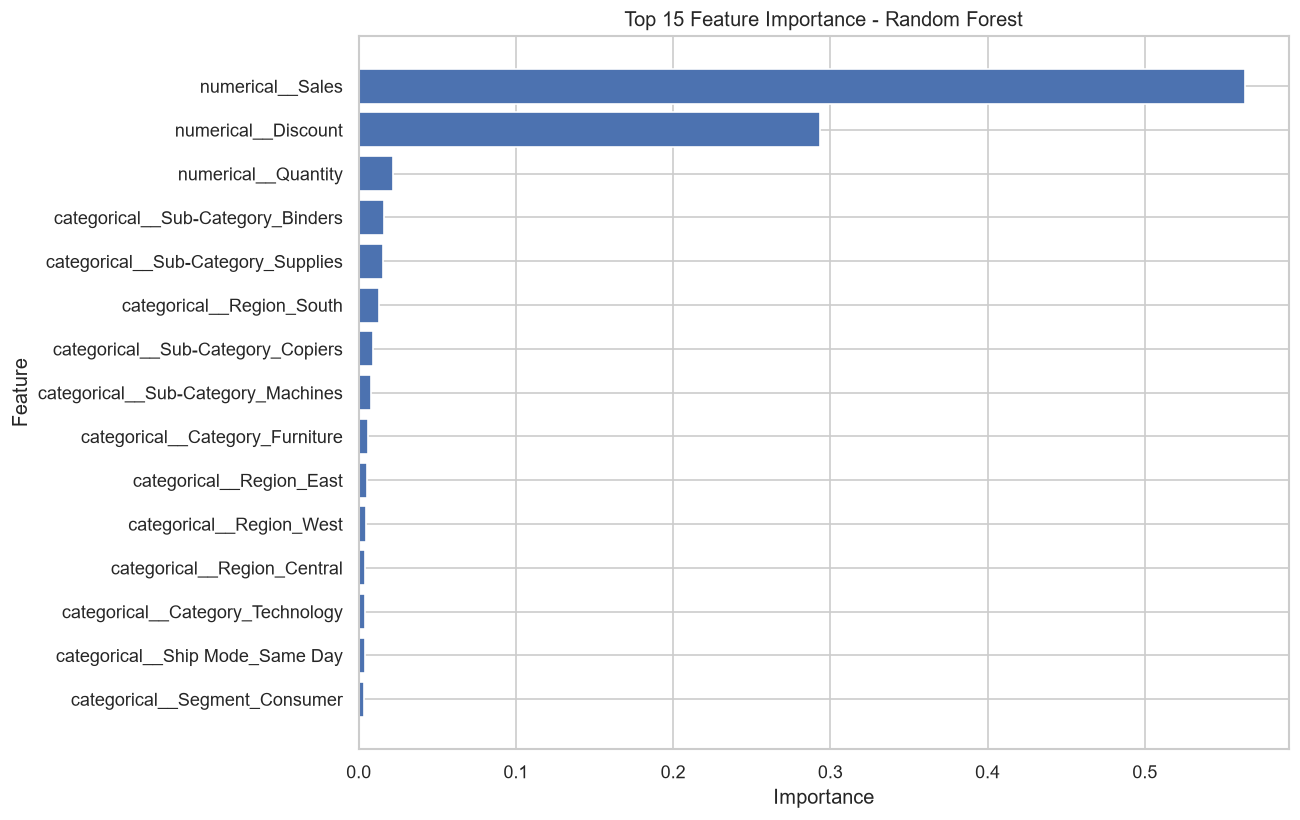

Feature importance saved successfully!


In [20]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 IMPORTANT FEATURES")

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "visualizations/18_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

importance_df.to_csv(
    "reports/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

In [21]:
joblib.dump(
    best_model,
    "models/random_forest_profit_model.pkl"
)

joblib.dump(
    preprocessor,
    "models/profit_preprocessor.pkl"
)

loaded_model = joblib.load(
    "models/random_forest_profit_model.pkl"
)

loaded_preprocessor = joblib.load(
    "models/profit_preprocessor.pkl"
)

print("Model and preprocessor saved and loaded successfully!")

Model and preprocessor saved and loaded successfully!


In [22]:
new_transaction = pd.DataFrame({
    "Sales": [250.00],
    "Quantity": [4],
    "Discount": [0.20],
    "Category": ["Office Supplies"],
    "Sub-Category": ["Binders"],
    "Region": ["Central"],
    "Segment": ["Consumer"],
    "Ship Mode": ["Standard Class"]
})

new_transaction_processed = loaded_preprocessor.transform(
    new_transaction
)

predicted_profit = loaded_model.predict(
    new_transaction_processed
)

print("NEW TRANSACTION:")
display(new_transaction)

print(
    "Predicted Profit:",
    round(predicted_profit[0], 2)
)

NEW TRANSACTION:


,Sales,Quantity,Discount,Category,Sub-Category,Region,Segment,Ship Mode
0,250.0,4,0.2,Office Supplies,Binders,Central,Consumer,Standard Class


Predicted Profit: 83.9


In [23]:
sample_transactions = pd.DataFrame({
    "Sales": [250, 500, 1200],
    "Quantity": [4, 5, 8],
    "Discount": [0.20, 0.10, 0.30],
    "Category": [
        "Office Supplies",
        "Technology",
        "Furniture"
    ],
    "Sub-Category": [
        "Binders",
        "Phones",
        "Chairs"
    ],
    "Region": [
        "Central",
        "West",
        "East"
    ],
    "Segment": [
        "Consumer",
        "Corporate",
        "Home Office"
    ],
    "Ship Mode": [
        "Standard Class",
        "First Class",
        "Second Class"
    ]
})

processed_transactions = loaded_preprocessor.transform(
    sample_transactions
)

batch_predictions = loaded_model.predict(
    processed_transactions
)

sample_transactions["Predicted_Profit"] = batch_predictions

display(sample_transactions.round(2))

sample_transactions.to_csv(
    "reports/sample_profit_predictions.csv",
    index=False
)

print("Batch predictions saved successfully!")

,Sales,Quantity,Discount,Category,Sub-Category,Region,Segment,Ship Mode,Predicted_Profit
0,250,4,0.2,Office Supplies,Binders,Central,Consumer,Standard Class,83.90
1,500,5,0.1,Technology,Phones,West,Corporate,First Class,100.07
2,1200,8,0.3,Furniture,Chairs,East,Home Office,Second Class,-111.39


Batch predictions saved successfully!


In [24]:
required_files = [
    "reports/descriptive_statistics.csv",
    "reports/correlation_analysis.csv",
    "reports/customer_segmentation.csv",
    "reports/customer_segment_profile.csv",
    "reports/model_evaluation_results.csv",
    "reports/feature_importance.csv",
    "reports/residual_analysis.csv",
    "reports/sample_profit_predictions.csv",
    "models/random_forest_profit_model.pkl",
    "models/profit_preprocessor.pkl",
    "visualizations/11_correlation_heatmap.png",
    "visualizations/12_elbow_method.png",
    "visualizations/13_silhouette_analysis.png",
    "visualizations/14_customer_segment_distribution.png",
    "visualizations/15_segment_sales_profit_comparison.png",
    "visualizations/16_actual_vs_predicted_profit.png",
    "visualizations/17_residual_analysis.png",
    "visualizations/18_feature_importance.png"
]

successful = 0
failed = 0

print("=" * 60)
print("TASK 4 - FINAL VALIDATION")
print("=" * 60)

for file in required_files:
    if os.path.exists(file):
        print("✓", file)
        successful += 1
    else:
        print("✗ MISSING:", file)
        failed += 1

print("\nTotal Files:", len(required_files))
print("Successful:", successful)
print("Missing:", failed)

if failed == 0:
    print("\nTASK 4 COMPLETED SUCCESSFULLY!")
else:
    print("\nPLEASE CHECK THE MISSING FILES.")

TASK 4 - FINAL VALIDATION
✓ ../reports/descriptive_statistics.csv
✓ ../reports/correlation_analysis.csv
✓ ../reports/customer_segmentation.csv
✓ ../reports/customer_segment_profile.csv
✓ ../reports/model_evaluation_results.csv
✓ ../reports/feature_importance.csv
✓ ../reports/residual_analysis.csv
✓ ../reports/sample_profit_predictions.csv
✓ ../models/random_forest_profit_model.pkl
✓ ../models/profit_preprocessor.pkl
✓ ../visualizations/11_correlation_heatmap.png
✓ ../visualizations/12_elbow_method.png
✓ ../visualizations/13_silhouette_analysis.png
✓ ../visualizations/14_customer_segment_distribution.png
✓ ../visualizations/15_segment_sales_profit_comparison.png
✓ ../visualizations/16_actual_vs_predicted_profit.png
✓ ../visualizations/17_residual_analysis.png
✓ ../visualizations/18_feature_importance.png

Total Files: 18
Successful: 18
Missing: 0

TASK 4 COMPLETED SUCCESSFULLY!


In [2]:
# 4.7 TIME-SERIES ANALYSIS

# This section analyzes daily, weekly, and monthly sales and profit trends using time-series resampling.

In [4]:
# ============================================================
# 4.7 TIME-SERIES ANALYSIS - DATA PREPARATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the filtered dataset
df_ts = pd.read_csv("data/time_series_analysis.csv")

# Convert Order Date to datetime
df_ts["Order Date"] = pd.to_datetime(df_ts["Order Date"])

# Set Order Date as index
df_ts = df_ts.set_index("Order Date").sort_index()

# Create output folder
os.makedirs("time_series_results", exist_ok=True)

# Check dataset
print("TIME-SERIES DATASET SUMMARY")
print("-" * 40)

print("Total Records:", len(df_ts))
print("Start Date:", df_ts.index.min().date())
print("End Date:", df_ts.index.max().date())
print("Missing Dates:", df_ts.index.isna().sum())

display(df_ts.head())

TIME-SERIES DATASET SUMMARY
----------------------------------------
Total Records: 9641
Start Date: 2023-01-03
End Date: 2026-11-24
Missing Dates: 0


,Row ID,Order ID,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
Order Date,,,,,,,,,,,,,,,,,,,,
2023-01-03,1,US-2023-103800,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
2023-01-04,2,US-2023-112326,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2023-01-04,3,US-2023-112326,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
2023-01-04,4,US-2023-112326,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
2023-01-05,5,US-2023-141817,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [5]:
# ============================================================
# DAILY, WEEKLY AND MONTHLY SALES & PROFIT ANALYSIS
# ============================================================

# Daily aggregation
daily_sales = df_ts.resample("D").agg({
    "Sales": "sum",
    "Profit": "sum"
})

# Weekly aggregation
weekly_sales = df_ts.resample("W").agg({
    "Sales": "sum",
    "Profit": "sum"
})

# Monthly aggregation
monthly_sales = df_ts.resample("ME").agg({
    "Sales": "sum",
    "Profit": "sum"
})

# Display results
print("DAILY SALES AND PROFIT")
display(daily_sales.head())

print("WEEKLY SALES AND PROFIT")
display(weekly_sales.head())

print("MONTHLY SALES AND PROFIT")
display(monthly_sales.head())

# Save results
daily_sales.to_csv("time_series_results/daily_sales_profit.csv")
weekly_sales.to_csv("time_series_results/weekly_sales_profit.csv")
monthly_sales.to_csv("time_series_results/monthly_sales_profit.csv")

print("All three time-series datasets saved successfully.")

DAILY SALES AND PROFIT


,Sales,Profit
Order Date,,
2023-01-03,16.448,5.5512
2023-01-04,288.060,-65.9901
2023-01-05,19.536,4.8840
2023-01-06,4407.100,1358.0524
2023-01-07,87.158,-71.9621


WEEKLY SALES AND PROFIT


,Sales,Profit
Order Date,,
2023-01-08,4818.302,1230.5354
2023-01-15,3871.019,722.9841
2023-01-22,3723.700,390.2276
2023-01-29,1573.868,180.5738
2023-02-05,1443.208,311.2429


MONTHLY SALES AND PROFIT


,Sales,Profit
Order Date,,
2023-01-31,14518.055,2539.3907
2023-02-28,4519.892,862.3084
2023-03-31,56933.909,693.4499
2023-04-30,28295.345,3488.8352
2023-05-31,26319.767,3196.3918


All three time-series datasets saved successfully.


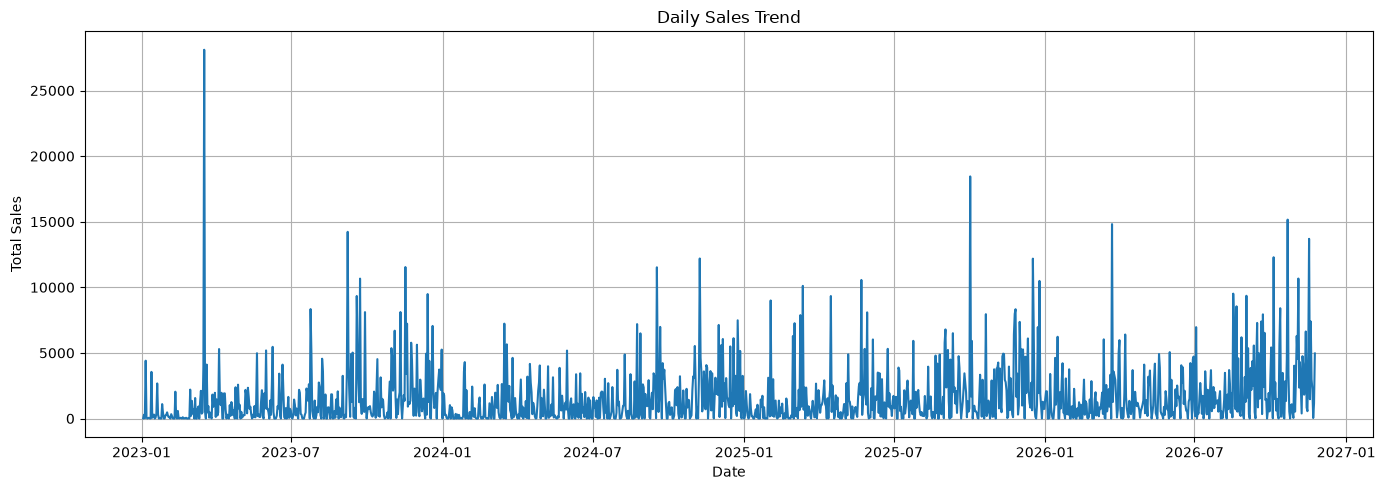

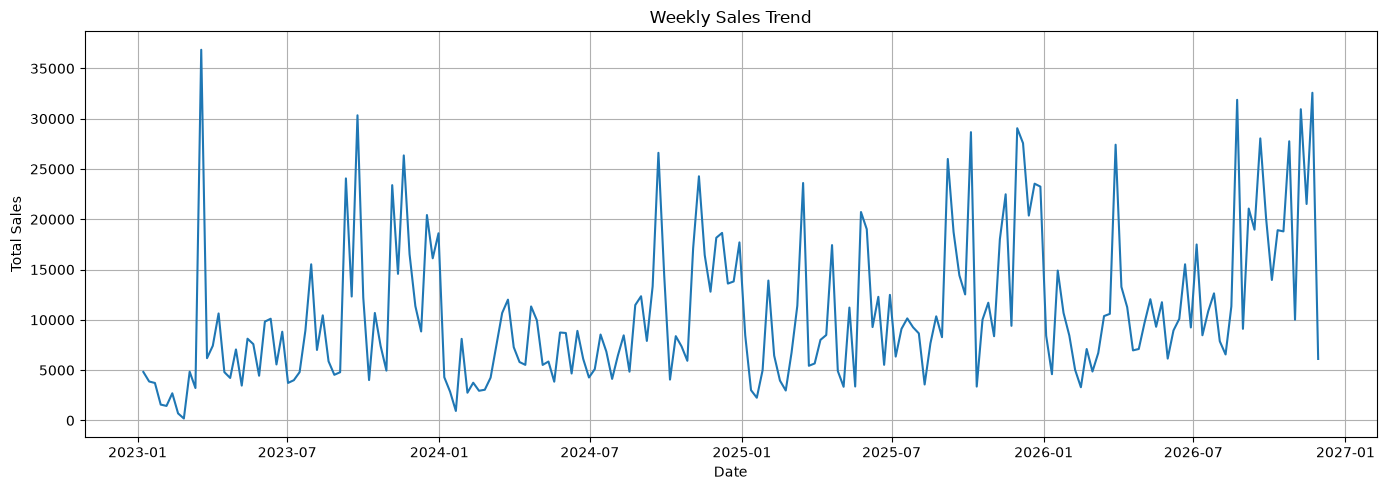

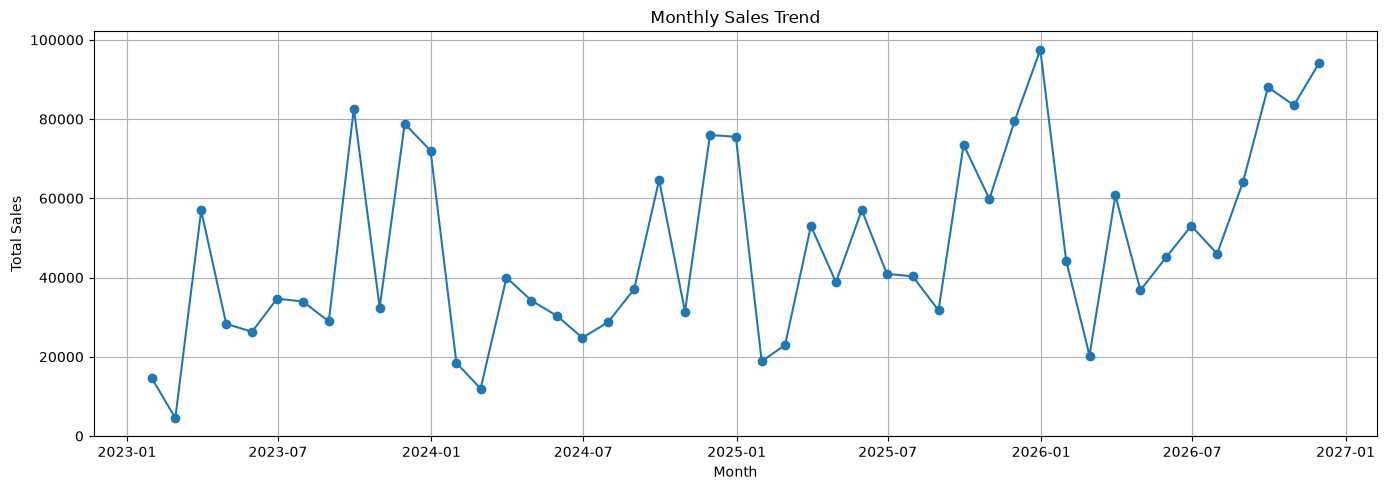

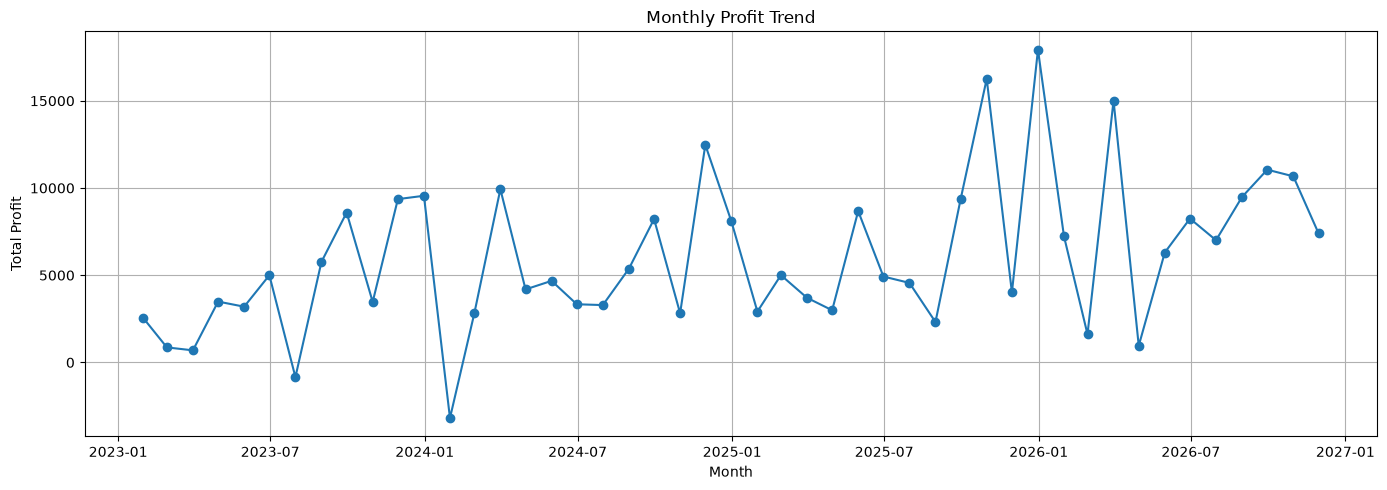

In [6]:
# ============================================================
# TIME-SERIES VISUALIZATION
# ============================================================

# Daily Sales
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales["Sales"])
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.savefig("time_series_results/daily_sales_trend.png")
plt.show()


# Weekly Sales
plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales["Sales"])
plt.title("Weekly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.savefig("time_series_results/weekly_sales_trend.png")
plt.show()


# Monthly Sales
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales["Sales"], marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.savefig("time_series_results/monthly_sales_trend.png")
plt.show()


# Monthly Profit
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales["Profit"], marker="o")
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.grid(True)
plt.tight_layout()
plt.savefig("time_series_results/monthly_profit_trend.png")
plt.show()

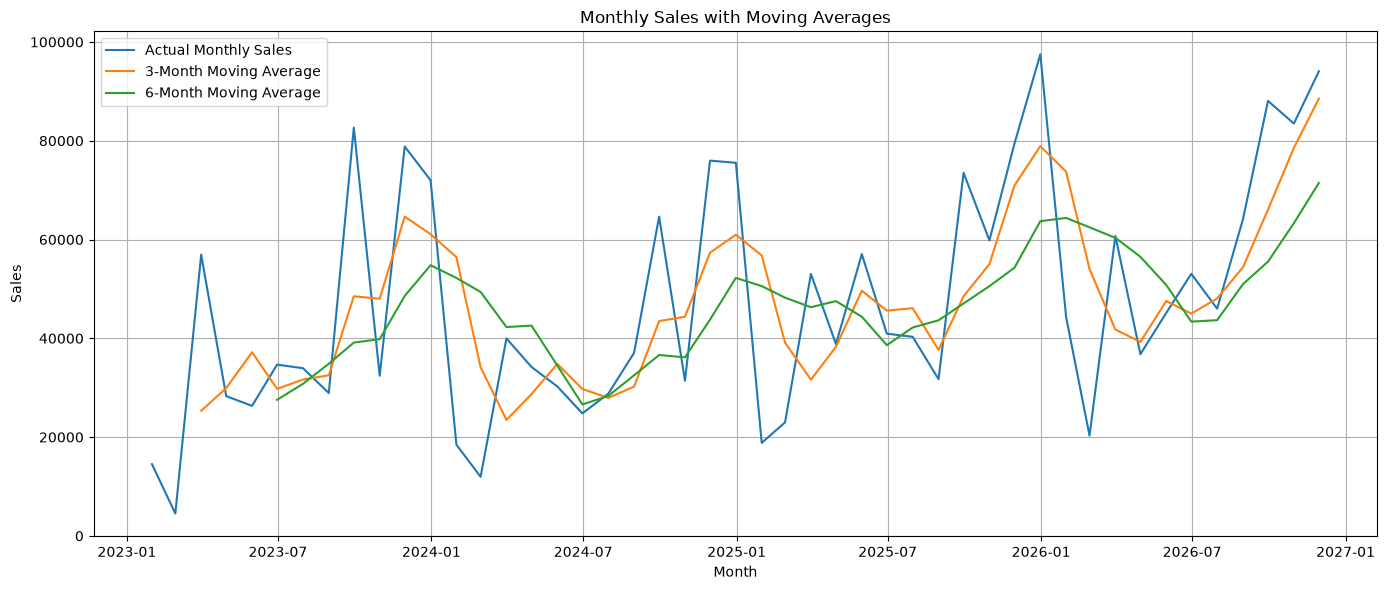

,Sales,Profit,Sales_MA_3,Sales_MA_6
Order Date,,,,
2025-12-31,97502.2770,17926.3013,78915.081267,63714.036667
2026-01-31,44259.2140,7231.6391,73724.485600,64373.822500
2026-02-28,20301.1334,1613.8720,54020.874800,62471.209017
2026-03-31,60728.4808,15013.0910,41762.942733,60339.012000
2026-04-30,36779.0361,957.5300,39269.550100,56497.017850
2026-05-31,45155.4822,6299.8072,47554.333033,50787.603917
2026-06-30,53056.0777,8246.5707,44996.865333,43379.904033
2026-07-31,45989.4960,7006.5012,48067.018633,43668.284367
2026-08-31,64129.7580,9488.0722,54391.777233,50973.055133


In [7]:
# ============================================================
# MOVING AVERAGE ANALYSIS
# ============================================================

monthly_sales["Sales_MA_3"] = (
    monthly_sales["Sales"].rolling(window=3).mean()
)

monthly_sales["Sales_MA_6"] = (
    monthly_sales["Sales"].rolling(window=6).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales["Sales"],
    label="Actual Monthly Sales"
)

plt.plot(
    monthly_sales.index,
    monthly_sales["Sales_MA_3"],
    label="3-Month Moving Average"
)

plt.plot(
    monthly_sales.index,
    monthly_sales["Sales_MA_6"],
    label="6-Month Moving Average"
)

plt.title("Monthly Sales with Moving Averages")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("time_series_results/moving_average_analysis.png")
plt.show()

display(monthly_sales.tail(12))

LAST THREE MONTHS SALES:


Order Date
2026-09-30    88064.5320
2026-10-31    83474.7832
2026-11-30    94071.8080
Freq: ME, Name: Sales, dtype: float64

NEXT THREE MONTHS SIMPLE FORECAST:


,Forecast_Sales
2026-12-31,88537.041067
2027-01-31,88537.041067
2027-02-28,88537.041067


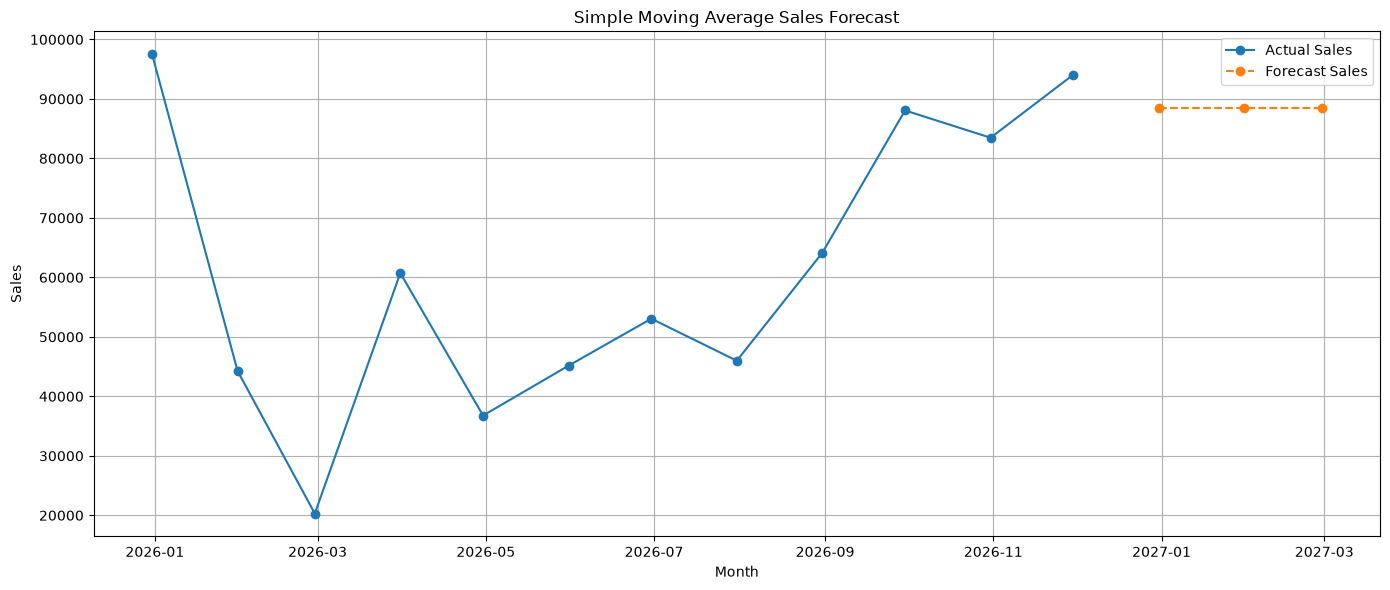

In [8]:
# ============================================================
# SIMPLE 3-MONTH MOVING AVERAGE FORECAST
# ============================================================

last_three_months = monthly_sales["Sales"].tail(3)

forecast_value = last_three_months.mean()

forecast_dates = pd.date_range(
    start=monthly_sales.index[-1] + pd.offsets.MonthEnd(1),
    periods=3,
    freq="ME"
)

forecast_df = pd.DataFrame({
    "Forecast_Sales": [forecast_value] * 3
}, index=forecast_dates)

print("LAST THREE MONTHS SALES:")
display(last_three_months)

print("NEXT THREE MONTHS SIMPLE FORECAST:")
display(forecast_df)

# Plot actual and forecast values
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index[-12:],
    monthly_sales["Sales"].tail(12),
    marker="o",
    label="Actual Sales"
)

plt.plot(
    forecast_df.index,
    forecast_df["Forecast_Sales"],
    marker="o",
    linestyle="--",
    label="Forecast Sales"
)

plt.title("Simple Moving Average Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("time_series_results/sales_forecast.png")
plt.show()

forecast_df.to_csv("time_series_results/sales_forecast.csv")

In [9]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\PRITWISH\OneDrive\Attachments\Desktop\apexplanet-data-analytics\.venv\Scripts\python.exe -m pip install --upgrade pip


C:\Users\PRITWISH\AppData\Local\Temp\ipykernel_22980\710772327.py:11: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(


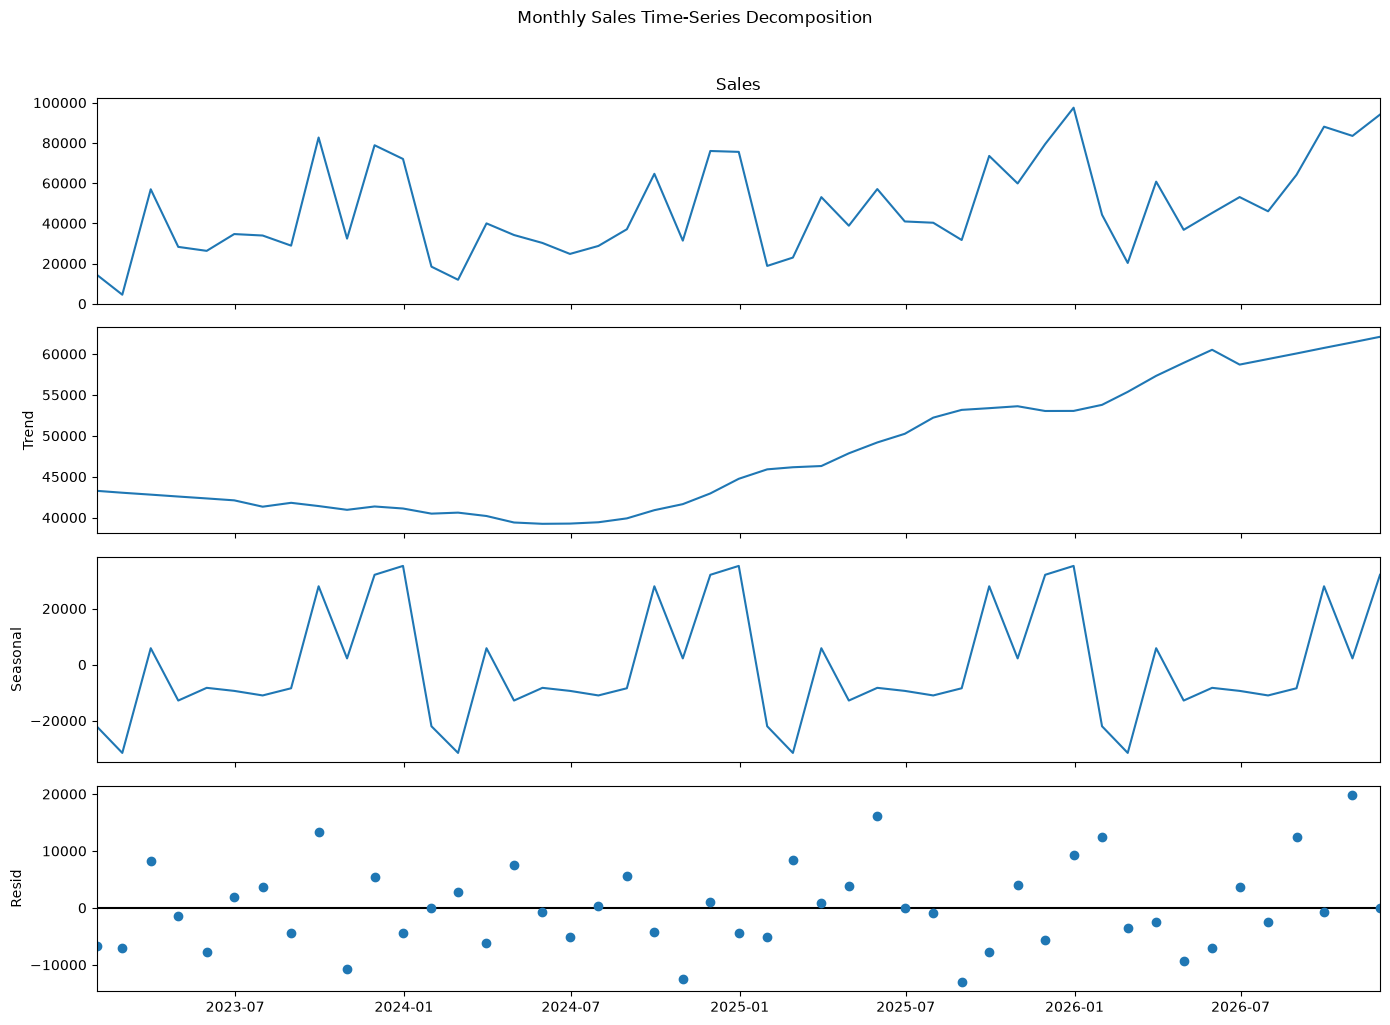

Time-series decomposition completed.


In [10]:
# ============================================================
# TIME-SERIES DECOMPOSITION
# ============================================================

from statsmodels.tsa.seasonal import seasonal_decompose

# Prepare monthly sales series
monthly_series = monthly_sales["Sales"].asfreq("ME")

# Decompose using a 12-month seasonal period
decomposition = seasonal_decompose(
    monthly_series,
    model="additive",
    period=12,
    extrapolate_trend="freq"
)

# Plot decomposition
fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.suptitle("Monthly Sales Time-Series Decomposition", y=1.02)

plt.tight_layout()
plt.savefig("time_series_results/sales_decomposition.png")
plt.show()

print("Time-series decomposition completed.")

In [11]:
# ============================================================
# HYPOTHESIS TESTING - CUSTOMER SEGMENTS
# ============================================================

from scipy.stats import ttest_ind

consumer_profit = df_ts.loc[
    df_ts["Segment"] == "Consumer", "Profit"
]

corporate_profit = df_ts.loc[
    df_ts["Segment"] == "Corporate", "Profit"
]

# Welch's independent two-sample t-test
t_statistic, p_value = ttest_ind(
    consumer_profit,
    corporate_profit,
    equal_var=False
)

alpha = 0.05

print("HYPOTHESIS TESTING RESULTS")
print("-" * 45)

print("Consumer Mean Profit:", consumer_profit.mean())
print("Corporate Mean Profit:", corporate_profit.mean())
print("T-statistic:", t_statistic)
print("P-value:", p_value)

if p_value < alpha:
    print("Result: Reject the null hypothesis.")
    print("There is statistically significant evidence of a difference.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference.")

HYPOTHESIS TESTING RESULTS
---------------------------------------------
Consumer Mean Profit: 26.289320482897384
Corporate Mean Profit: 31.89173871297242
T-statistic: -1.0204480208436228
P-value: 0.3075539261089628
Result: Fail to reject the null hypothesis.
There is insufficient evidence of a difference.


<Figure size 1000x600 with 0 Axes>

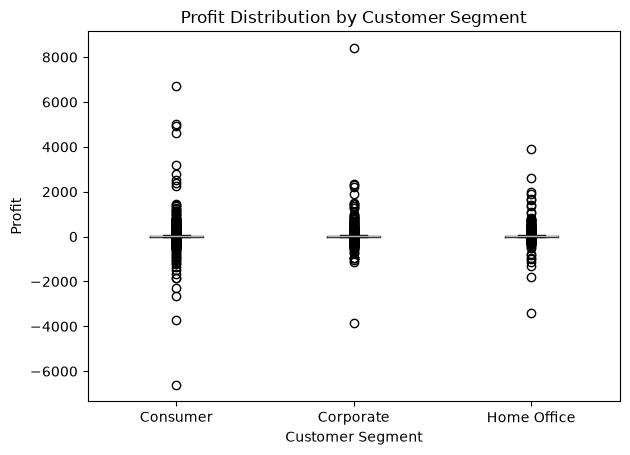

In [12]:
# ============================================================
# PROFIT DISTRIBUTION BY CUSTOMER SEGMENT
# ============================================================

plt.figure(figsize=(10, 6))

df_ts.boxplot(
    column="Profit",
    by="Segment",
    grid=False
)

plt.title("Profit Distribution by Customer Segment")
plt.suptitle("")
plt.xlabel("Customer Segment")
plt.ylabel("Profit")

plt.tight_layout()
plt.savefig("time_series_results/profit_by_segment_boxplot.png")
plt.show()

In [13]:
# ============================================================
# PRINCIPAL COMPONENT ANALYSIS (PCA)
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numerical features
pca_features = df_ts[
    ["Sales", "Quantity", "Discount"]
].copy()

# Standardize features
scaler_pca = StandardScaler()

scaled_features = scaler_pca.fit_transform(pca_features)

# Apply PCA
pca = PCA(n_components=2)

pca_result = pca.fit_transform(scaled_features)

# Create DataFrame
pca_df = pd.DataFrame(
    pca_result,
    columns=["Principal Component 1", "Principal Component 2"]
)

print("PCA EXPLAINED VARIANCE")
print("-" * 40)

print("PC1:", pca.explained_variance_ratio_[0])
print("PC2:", pca.explained_variance_ratio_[1])

print(
    "Total Variance Explained:",
    pca.explained_variance_ratio_.sum()
)

display(pca_df.head())

PCA EXPLAINED VARIANCE
----------------------------------------
PC1: 0.39982699117852416
PC2: 0.3336137578403838
Total Variance Explained: 0.7334407490189079


,Principal Component 1,Principal Component 2
0,-0.820983,0.103529
1,-1.090698,2.979314
2,-0.511261,0.166092
3,-0.218788,0.160021
4,-0.502572,0.165912


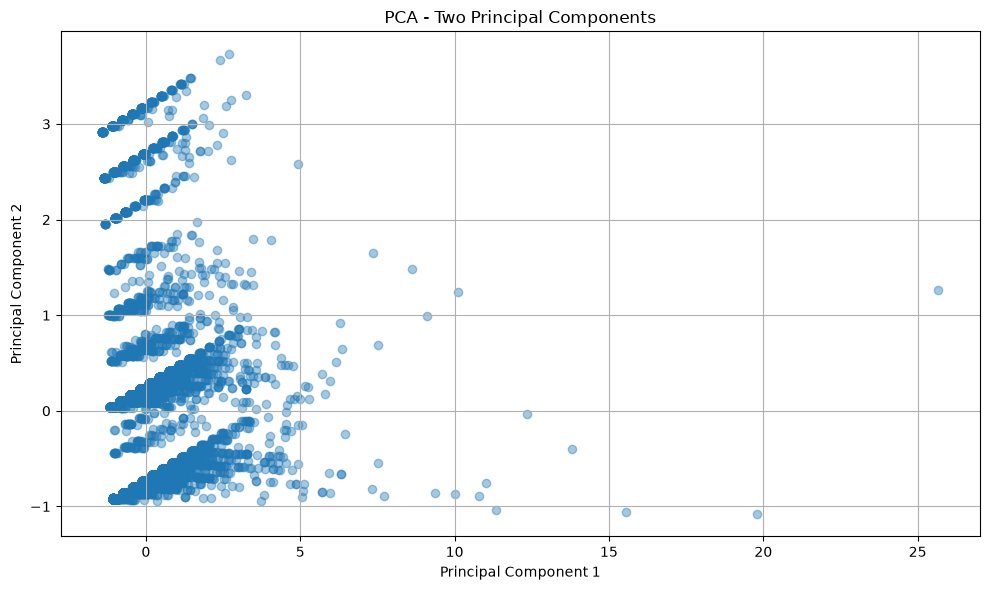

In [14]:
# ============================================================
# PCA SCATTER PLOT
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    pca_df["Principal Component 1"],
    pca_df["Principal Component 2"],
    alpha=0.4
)

plt.title("PCA - Two Principal Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)

plt.tight_layout()
plt.savefig("time_series_results/pca_visualization.png")
plt.show()

In [15]:
# ============================================================
# SAVE PCA RESULTS
# ============================================================

pca_df["Segment"] = df_ts["Segment"].reset_index(drop=True)

pca_df.to_csv(
    "time_series_results/pca_results.csv",
    index=False
)

print("PCA results saved successfully.")

PCA results saved successfully.


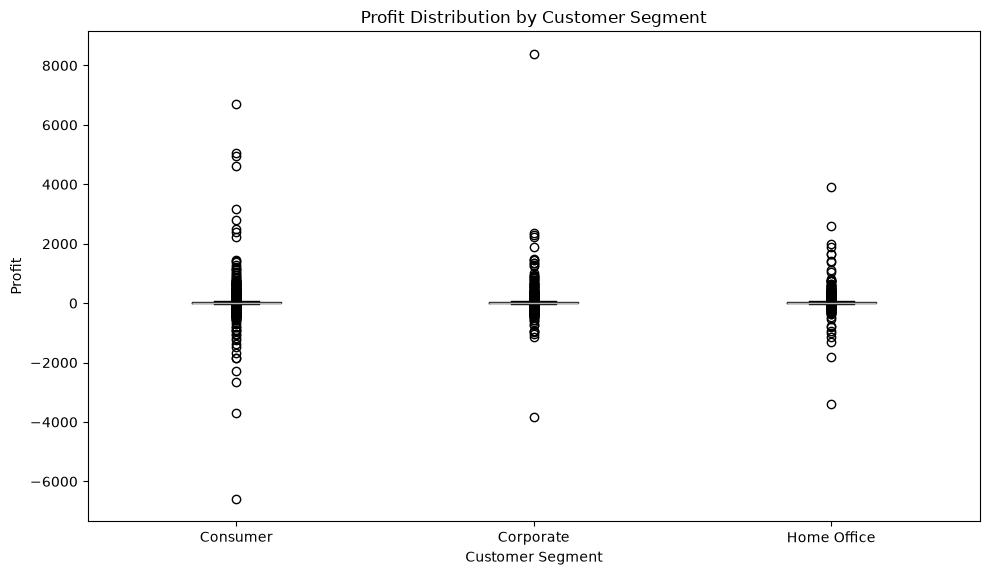

Profit distribution visualization saved successfully!


In [16]:
# ============================================================
# FIXED: PROFIT DISTRIBUTION BY CUSTOMER SEGMENT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

df_ts.boxplot(
    column="Profit",
    by="Segment",
    grid=False,
    ax=ax
)

ax.set_title("Profit Distribution by Customer Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Profit")

plt.suptitle("")
plt.tight_layout()

plt.savefig(
    "time_series_results/profit_by_segment_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Profit distribution visualization saved successfully!")

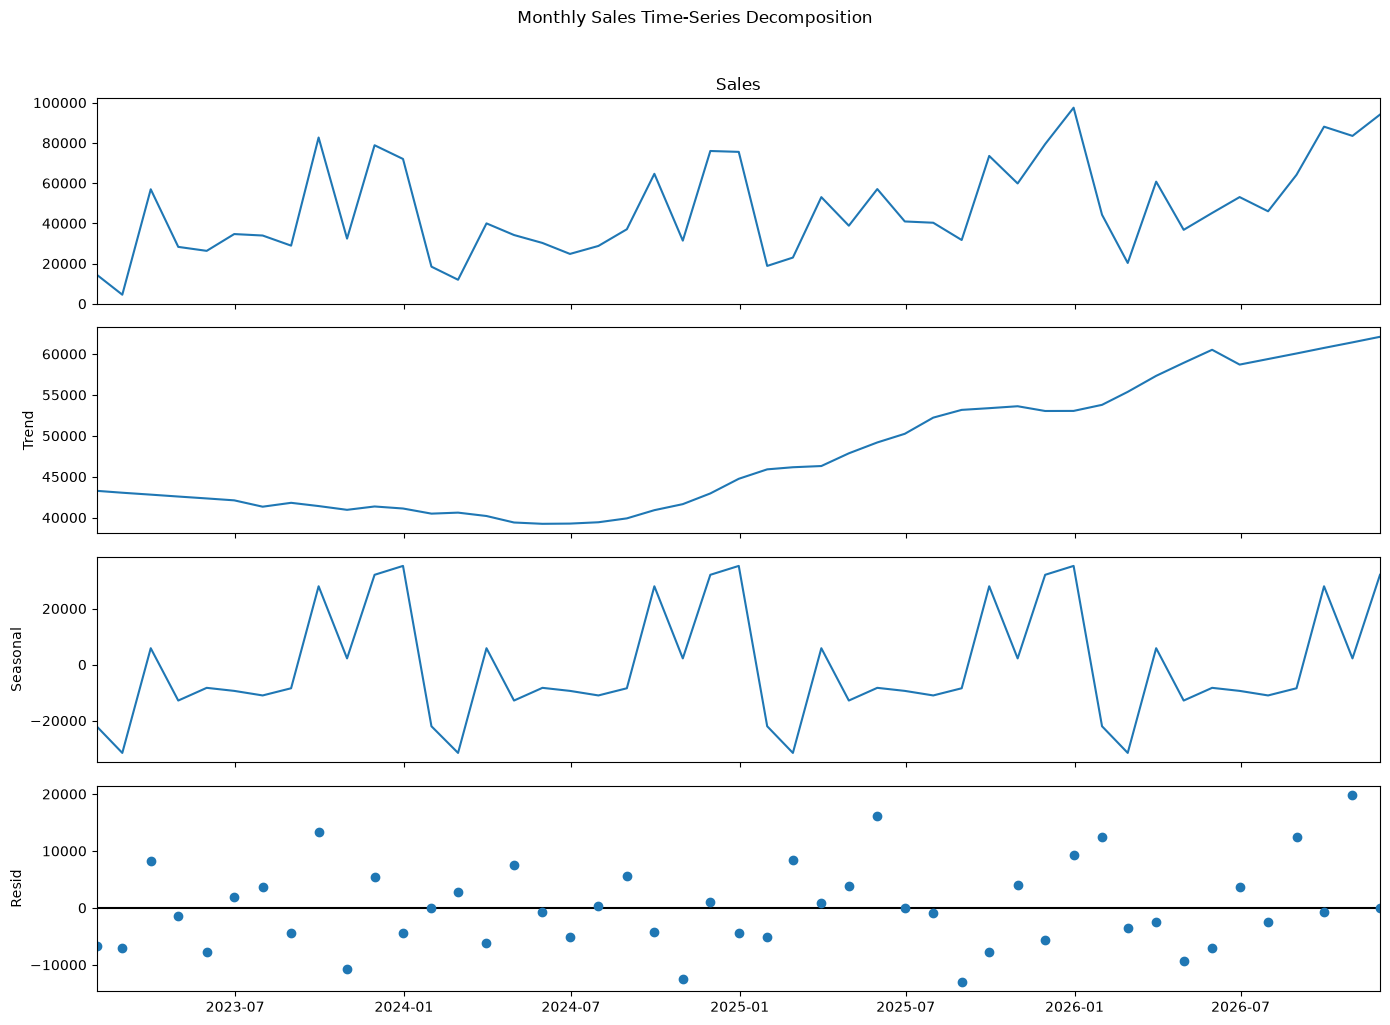

Updated decomposition completed successfully!


In [17]:
# ============================================================
# UPDATED TIME-SERIES DECOMPOSITION
# ============================================================

from statsmodels.tsa.seasonal import seasonal_decompose

monthly_series = monthly_sales["Sales"].asfreq("ME")

decomposition = seasonal_decompose(
    monthly_series,
    model="additive",
    period=12,
    extrapolate_trend="period"
)

fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.suptitle("Monthly Sales Time-Series Decomposition", y=1.02)

plt.tight_layout()

plt.savefig(
    "time_series_results/sales_decomposition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Updated decomposition completed successfully!")

In [18]:
# ============================================================
# TIME-SERIES SUMMARY REPORT
# ============================================================

summary = pd.DataFrame({
    "Metric": [
        "Total Time-Series Records",
        "Total Sales",
        "Total Profit",
        "Average Monthly Sales",
        "Average Monthly Profit",
        "Highest Monthly Sales",
        "Lowest Monthly Sales",
        "Average 3-Month Forecast"
    ],

    "Value": [
        len(df_ts),
        df_ts["Sales"].sum(),
        df_ts["Profit"].sum(),
        monthly_sales["Sales"].mean(),
        monthly_sales["Profit"].mean(),
        monthly_sales["Sales"].max(),
        monthly_sales["Sales"].min(),
        forecast_value
    ]
})

display(summary.round(2))

summary.to_csv(
    "time_series_results/time_series_summary.csv",
    index=False
)

print("Time-series summary report saved successfully!")

,Metric,Value
0,Total Time-Series Records,9641.00
1,Total Sales,2216976.62
2,Total Profit,281358.67
3,Average Monthly Sales,47169.72
4,Average Monthly Profit,5986.35
5,Highest Monthly Sales,97502.28
6,Lowest Monthly Sales,4519.89
7,Average 3-Month Forecast,88537.04


Time-series summary report saved successfully!


# 4.8 ADVANCED ANALYTICS - KEY FINDINGS

## 1. Time-Series Analysis
- Daily, weekly and monthly sales and profit were calculated.
- Moving averages were used to identify underlying sales trends.
- A simple three-month moving average was used to forecast sales.
- Seasonal decomposition separated trend, seasonality and residual components.

## 2. Hypothesis Testing
- Welch's independent two-sample t-test compared Consumer and Corporate profit.
- The p-value was approximately 0.3076.
- At a 5% significance level, the null hypothesis was not rejected.
- The analysis did not find sufficient evidence of a difference in average transaction profit.

## 3. Principal Component Analysis
- PCA was applied to Sales, Quantity and Discount.
- Two principal components explained approximately 73.34% of the total variance.

## 4. Predictive Modeling
- Dummy Regressor, Linear Regression and Random Forest were evaluated.
- Random Forest achieved the best test-set performance.
- R² Score: 0.7879.
- MAE: 20.4557.
- RMSE: 137.9378.

## 5. Customer Segmentation
- K-Means clustering was used to identify customer groups.
- Cluster profiles were compared using average sales and profit.
- The results support differentiated customer engagement strategies.